# Lab 14: Saturation and Diminishing Returns

This lab shows how the Hill saturation transform turns adstocked media into a diminishing-returns response.
It applies the transform to an actual Sedge channel series and accompanies Chapter 14 of the book Marketing Mix Modelling.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.plotting import mmm_style
from mmm_book.saturation import hill_saturation
from mmm_book.sedge import ADSTOCK_ALPHA, HILL_SLOPE, generate_sedge

mmm_style()

## The Hill curve

The Hill transform maps a non-negative input to a response in [0, 1).
`half` is the half-saturation point, the input level at which the response reaches 0.5, and `slope` sets the shape: they are the book's $k$ and $s$ in $f(x) = x^s / (x^s + k^s)$.
A slope of 1 gives the concave curve the case-study model uses, bending over from the first pound; a higher slope gives an S-shape, with a steeper rise around `half` and a harder ceiling above it.
The plot below shows the curve for a few combinations of `half` and `slope`.

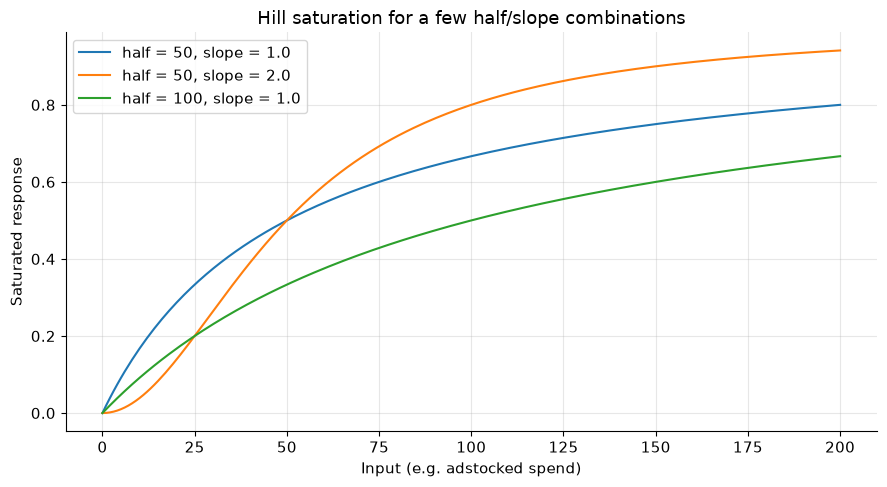

In [2]:
x = np.linspace(0, 200, 200)

combos = [(50, 1.0), (50, 2.0), (100, 1.0)]

fig, ax = plt.subplots()
for half, slope in combos:
    response = hill_saturation(x, half=half, slope=slope)
    ax.plot(x, response, label=f"half = {half}, slope = {slope}")

ax.set_xlabel("Input (e.g. adstocked spend)")
ax.set_ylabel("Saturated response")
ax.set_title("Hill saturation for a few half/slope combinations")
ax.legend()
fig.tight_layout()

## Saturation applied to an actual Sedge channel series

Real media is rarely presented to the saturation curve directly.
It is first adstocked so that carryover is accounted for, and only then saturated.
The cell below takes one region's Paid Search driver from the Sedge dataset, its generic search impressions (brand search follows demand rather than creating it, so the generator drives Search's effect from generic impressions), adstocks it with the channel's own `ADSTOCK_ALPHA`, and saturates it with the channel's own `HILL_SLOPE`.
This mirrors how the Sedge generator builds each channel's response shape, so the plot shows a correctly-specified saturation curve for a bursty series.
The half-saturation point is `HALF_MULT[channel]` times the mean adstocked driver (the book's $k$ written as a multiple of average activity): Search's multiple, 0.92, puts the half-saturation point just below average activity, so Search is deep into its curve at actual spend, while Television's, about 14, keeps it on the steep part of its curve.

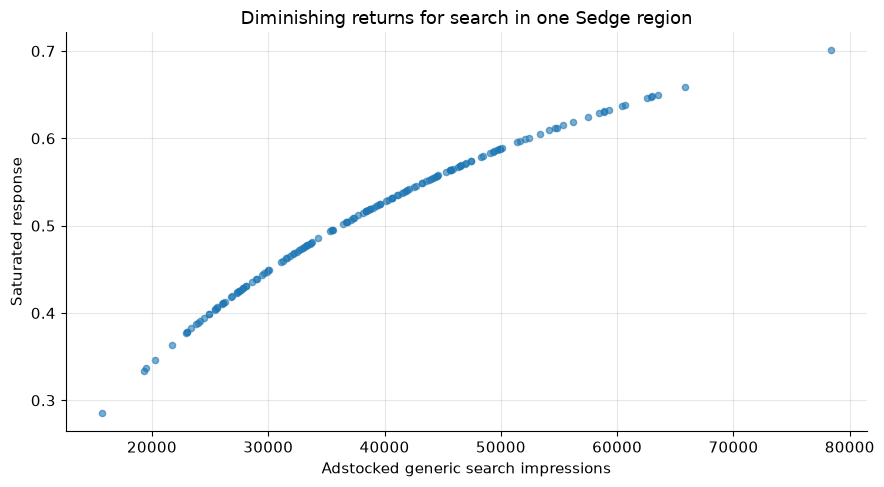

In [3]:
from mmm_book.sedge import HALF_MULT

df = generate_sedge(seed=RANDOM_SEED)
channel = "search"
driver = df.loc[df["region"] == "region_0", "search_generic_impr"].to_numpy(dtype=float)

adstocked = geometric_adstock(driver, alpha=ADSTOCK_ALPHA[channel], normalize=True)
half = HALF_MULT[channel] * float(np.mean(adstocked))
saturated = hill_saturation(adstocked, half=half, slope=HILL_SLOPE[channel])

fig, ax = plt.subplots()
ax.scatter(adstocked, saturated, alpha=0.6, s=20)
ax.set_xlabel("Adstocked generic search impressions")
ax.set_ylabel("Saturated response")
ax.set_title("Diminishing returns for search in one Sedge region")
fig.tight_layout()

## Takeaway

Saturation caps the marginal value of additional spend: once a channel is well past its half-saturation point, more spend buys very little extra response.
The half and slope parameters ($k$ and $s$) are properties of a channel, not free knobs to fit blindly, since they interact with adstock and with the overall scale of the media variable.
Labs 15 and 17 build a model that estimates media contributions using saturation shapes like these as fixed, correctly-specified features.